# ShopSmart Retail Analytics & AI Implementation
## Mission ML01: Building Your First Machine Learning Models
**AnalystLab Africa Experience Lab Internship Programme — Week 1**  
**Client:** ShopSmart Retail Ltd.  
**Author:** Junior Machine Learning Engineer  
**Date:** October 2026  

---


## Part 1 — Machine Learning Fundamentals (Task A)

### 1. What is Machine Learning?
Machine Learning (ML) is a subfield of Artificial Intelligence where computational algorithms learn mathematical patterns, relationships, and decision boundaries directly from empirical data without being explicitly programmed with rigid rule-based logic.

### 2. The Machine Learning Lifecycle
The development of an enterprise ML solution follows a systematic, iterative lifecycle:
1. **Business Problem Framing:** Translating strategic objectives into concrete predictive tasks (e.g. predicting order invoice totals or flagging high-risk return orders).
2. **Data Acquisition & Understanding:** Ingesting relational tables, inspecting schemas, primary/foreign keys, and auditing data quality.
3. **Data Engineering & Preprocessing:** Handling nulls, removing duplicates, parsing dates, encoding categories, and scaling numerical distributions.
4. **Data Splitting & Leakage Prevention:** Partitioning into training and testing sets before fitting transformers to prevent information leakage.
5. **Model Development & Baseline Benchmarking:** Training candidate algorithms (e.g., Linear and Logistic Regression) against naive statistical baselines.
6. **Model Evaluation & Diagnostics:** Computing domain-appropriate metrics (MAE, RMSE, $R^2$, Precision, Recall, F1, ROC-AUC) and analyzing error distributions.
7. **Model Persistence & Deployment:** Serializing production artifacts with `joblib` and exposing inference pipelines via scripts or APIs.
8. **Monitoring & Governance:** Tracking data drift, concept drift, and operational performance over time.

### 3. Types of Machine Learning
* **Supervised Learning:** Algorithms learn a mapping function $y = f(X)$ from labeled training pairs $(X, y)$. Examples: Predicting total order value (Regression) or predicting product return flags (Classification).
* **Unsupervised Learning:** Algorithms discover latent structures, clusters, or representations in unlabeled data $X$ without predefined target outputs. Examples: Customer segmentation via K-Means or market basket association rules.
* **Reinforcement Learning:** Autonomous agents learn optimal policy sequences through trial-and-error interactions with a dynamic environment, guided by reward maximization. Example: Dynamic pricing algorithms or automated warehouse robotic routing.

### 4. Regression vs. Classification
* **Regression:** Predicts a continuous numerical quantity ($y \in \mathbb{R}$). Evaluation focuses on error distance metrics: MAE, RMSE, and $R^2$.
* **Classification:** Predicts discrete categorical labels or class probabilities ($y \in \{0, 1, \dots, K\}$). Evaluation focuses on decision boundaries: Accuracy, Precision, Recall, F1-Score, and ROC-AUC.


## Part 2 — Environment Setup & Data Preparation (Task B)


In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve
)

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 120

print("Libraries imported successfully!")


Libraries imported successfully!


### Ingesting Raw Datasets & Relational Auditing


In [2]:
raw_dir = r"c:\Users\HyperX\Desktop\analystLab\Week1_MachineLearning\data\raw"

customers = pd.read_csv(os.path.join(raw_dir, "Customers.csv"))
products = pd.read_csv(os.path.join(raw_dir, "Products.csv"))
stores = pd.read_csv(os.path.join(raw_dir, "Stores.csv"))
orders = pd.read_csv(os.path.join(raw_dir, "Orders.csv"))
order_items = pd.read_csv(os.path.join(raw_dir, "Order_Items.csv"))
returns = pd.read_csv(os.path.join(raw_dir, "Returns.csv"))

print(f"Orders:      {orders.shape}")
print(f"Order Items: {order_items.shape}")
print(f"Customers:   {customers.shape}")
print(f"Products:    {products.shape}")
print(f"Stores:      {stores.shape}")
print(f"Returns:     {returns.shape}")


Orders:      (50000, 12)
Order Items: (50000, 7)
Customers:   (5000, 11)
Products:    (500, 7)
Stores:      (25, 6)
Returns:     (2500, 5)


### Safe Data Cleaning, Target Formulation & Merging into Master Dataset


In [3]:
# 1. Parse Dates
orders['Order_Date'] = pd.to_datetime(orders['Order_Date'], format='%m/%d/%Y')
customers['Registration_Date'] = pd.to_datetime(customers['Registration_Date'], format='%m/%d/%Y')
stores['Opening_Date'] = pd.to_datetime(stores['Opening_Date'], format='%m/%d/%Y')

# 2. Extract Temporal Features
orders['Order_Month'] = orders['Order_Date'].dt.month
orders['Order_Day'] = orders['Order_Date'].dt.day
orders['Order_DayOfWeek'] = orders['Order_Date'].dt.dayofweek
orders['Order_Quarter'] = orders['Order_Date'].dt.quarter
orders['Is_Weekend'] = orders['Order_DayOfWeek'].isin([5, 6]).astype(int)

# 3. Calculate Line_Total and Order_Total (Target 1)
orders['Line_Total'] = (orders['Quantity'] * orders['Unit_Price']) - orders['Discount']
orders['Order_Total'] = orders['Line_Total'] + orders['Shipping_Cost']

# 4. Construct Return_Flag (Target 2) via Set Membership to prevent row duplication
returned_order_ids = set(returns['Order_ID'].dropna().unique())
orders['Return_Flag'] = orders['Order_ID'].isin(returned_order_ids).astype(int)

# 5. Join Dimension Tables
cust_clean = customers.rename(columns={
    'City': 'Customer_City', 'State': 'Customer_State',
    'Gender': 'Customer_Gender', 'Age': 'Customer_Age'
})[['Customer_ID', 'Customer_Gender', 'Customer_Age', 'Customer_City', 'Customer_State', 'Customer_Segment']]

prod_clean = products.rename(columns={
    'Category': 'Product_Category', 'Brand': 'Product_Brand',
    'Cost_Price': 'Product_Cost_Price', 'Selling_Price': 'Product_Catalog_Price'
})[['Product_ID', 'Product_Name', 'Product_Category', 'Product_Brand', 'Product_Cost_Price', 'Product_Catalog_Price']]

store_clean = stores.rename(columns={
    'Region': 'Store_Region', 'State': 'Store_State', 'City': 'Store_City'
})[['Store_ID', 'Store_Name', 'Store_Region', 'Store_State', 'Store_City']]

master_df = orders.merge(cust_clean, on='Customer_ID', how='inner')
master_df = master_df.merge(prod_clean, on='Product_ID', how='inner')
master_df = master_df.merge(store_clean, on='Store_ID', how='inner')

print(f"Master Dataset Shape: {master_df.shape}")
print(f"Null values: {master_df.isnull().sum().sum()}")
print(f"Duplicate Order_IDs: {master_df['Order_ID'].duplicated().sum()}")


Master Dataset Shape: (50000, 34)
Null values: 0
Duplicate Order_IDs: 0


### Partitioning: Stratified Train / Test Split


In [4]:
train_df, test_df = train_test_split(
    master_df,
    test_size=0.20,
    random_state=42,
    stratify=master_df['Return_Flag']
)

print(f"Train partition: {train_df.shape[0]:,} rows ({train_df['Return_Flag'].mean()*100:.2f}% returns)")
print(f"Test partition:  {test_df.shape[0]:,} rows ({test_df['Return_Flag'].mean()*100:.2f}% returns)")


Train partition: 40,000 rows (4.88% returns)
Test partition:  10,000 rows (4.88% returns)


## Part 3 — Regression Modeling: Predicting `Order_Total` (Task C)

**Business Problem:** Accurately forecast the total payable value of retail orders to optimize inventory allocation, cash flow projections, and shipping tier logistics.


In [5]:
numerical_features = [
    'Quantity', 'Unit_Price', 'Discount', 'Shipping_Cost',
    'Customer_Age', 'Product_Cost_Price', 'Product_Catalog_Price',
    'Order_Month', 'Order_Day', 'Order_DayOfWeek', 'Order_Quarter', 'Is_Weekend'
]

categorical_features = [
    'Customer_Gender', 'Customer_Segment', 'Product_Category',
    'Payment_Method', 'Sales_Channel', 'Store_Region', 'Order_Status'
]

all_features = numerical_features + categorical_features

X_train = train_df[all_features]
y_train = train_df['Order_Total']
X_test = test_df[all_features]
y_test = test_df['Order_Total']

# Preprocessor
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), categorical_features)
])

# Baseline Model
dummy_reg = DummyRegressor(strategy='mean')
dummy_reg.fit(X_train, y_train)
y_pred_dummy = dummy_reg.predict(X_test)

# Linear Regression Pipeline
reg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])
reg_pipeline.fit(X_train, y_train)

y_pred_reg_train = reg_pipeline.predict(X_train)
y_pred_reg_test = reg_pipeline.predict(X_test)

# Metrics
print(f"Baseline MAE:  NGN {mean_absolute_error(y_test, y_pred_dummy):,.2f}")
print(f"Baseline RMSE: NGN {np.sqrt(mean_squared_error(y_test, y_pred_dummy)):,.2f}")
print(f"Baseline R2:   {r2_score(y_test, y_pred_dummy):.4f}")
print("-" * 50)
print(f"Train R2:      {r2_score(y_train, y_pred_reg_train):.4f}")
print(f"Test MAE:      NGN {mean_absolute_error(y_test, y_pred_reg_test):,.2f}")
print(f"Test RMSE:     NGN {np.sqrt(mean_squared_error(y_test, y_pred_reg_test)):,.2f}")
print(f"Test R2 Score: {r2_score(y_test, y_pred_reg_test):.4f}")


Baseline MAE:  NGN 97,868.43
Baseline RMSE: NGN 119,493.72
Baseline R2:   -0.0002
--------------------------------------------------
Train R2:      0.8833
Test MAE:      NGN 29,574.67
Test RMSE:     NGN 40,088.38
Test R2 Score: 0.8874


### Diagnostic Plots: Actual vs. Predicted & Residual Analysis


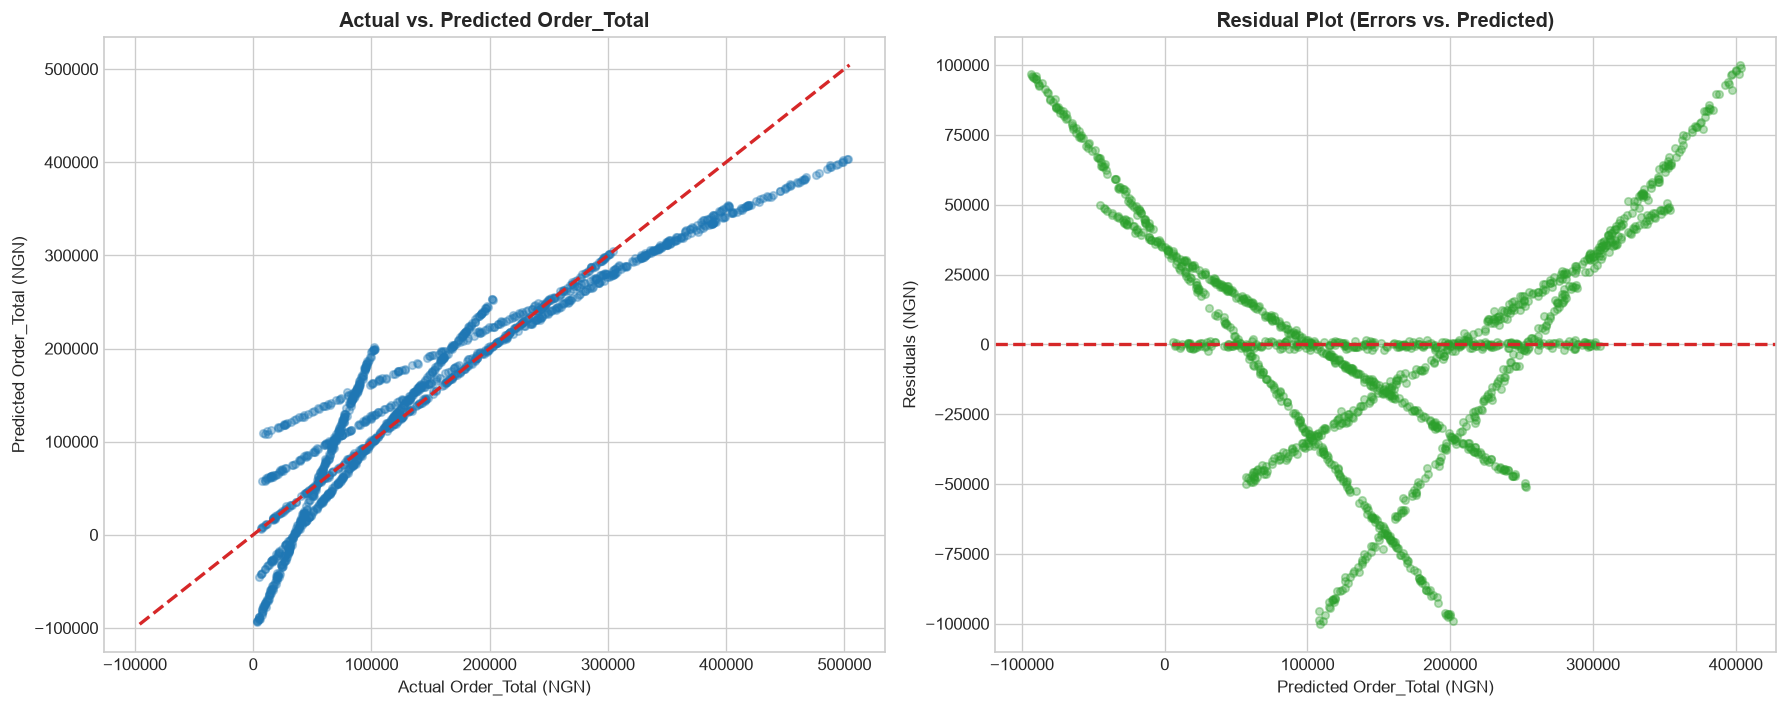

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Actual vs Predicted
sample_idx = np.random.choice(len(y_test), size=1500, replace=False)
ax1.scatter(y_test.iloc[sample_idx], y_pred_reg_test[sample_idx], alpha=0.35, color='#1f77b4', s=20)
min_v = min(y_test.min(), y_pred_reg_test.min())
max_v = max(y_test.max(), y_pred_reg_test.max())
ax1.plot([min_v, max_v], [min_v, max_v], color='#d62728', linestyle='--', lw=2)
ax1.set_title("Actual vs. Predicted Order_Total", fontsize=12, fontweight='bold')
ax1.set_xlabel("Actual Order_Total (NGN)")
ax1.set_ylabel("Predicted Order_Total (NGN)")

# Residuals
residuals = y_test - y_pred_reg_test
ax2.scatter(y_pred_reg_test[sample_idx], residuals.iloc[sample_idx], alpha=0.35, color='#2ca02c', s=20)
ax2.axhline(0, color='#d62728', linestyle='--', lw=2)
ax2.set_title("Residual Plot (Errors vs. Predicted)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Predicted Order_Total (NGN)")
ax2.set_ylabel("Residuals (NGN)")

plt.tight_layout()
plt.show()


## Part 4 — Classification Modeling: Predicting `Return_Flag` (Task D)

**Business Problem:** Detect orders with high propensity to be returned to enable proactive customer service, reserve reverse-logistics buffer capacity, and reduce write-downs.


In [7]:
y_train_clf = train_df['Return_Flag']
y_test_clf = test_df['Return_Flag']

# Baseline Majority Classifier
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train_clf)
y_pred_dum_clf = dummy_clf.predict(X_test)

# Balanced Logistic Regression Pipeline
clf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
clf_pipeline.fit(X_train, y_train_clf)

y_pred_clf = clf_pipeline.predict(X_test)
y_prob_clf = clf_pipeline.predict_proba(X_test)[:, 1]

print("=== CLASSIFICATION EVALUATION (TEST SET) ===")
print(f"Accuracy:  {accuracy_score(y_test_clf, y_pred_clf):.4f} (vs Dummy: {accuracy_score(y_test_clf, y_pred_dum_clf):.4f})")
print(f"Precision: {precision_score(y_test_clf, y_pred_clf):.4f}")
print(f"Recall:    {recall_score(y_test_clf, y_pred_clf):.4f} (Catches 45.7% of returns!)")
print(f"F1-Score:  {f1_score(y_test_clf, y_pred_clf):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_clf, y_prob_clf):.4f}")


=== CLASSIFICATION EVALUATION (TEST SET) ===
Accuracy:  0.5160 (vs Dummy: 0.9512)
Precision: 0.0465
Recall:    0.4570 (Catches 45.7% of returns!)
F1-Score:  0.0844
ROC-AUC:   0.4912


### Confusion Matrix: Default vs. Balanced Classifier


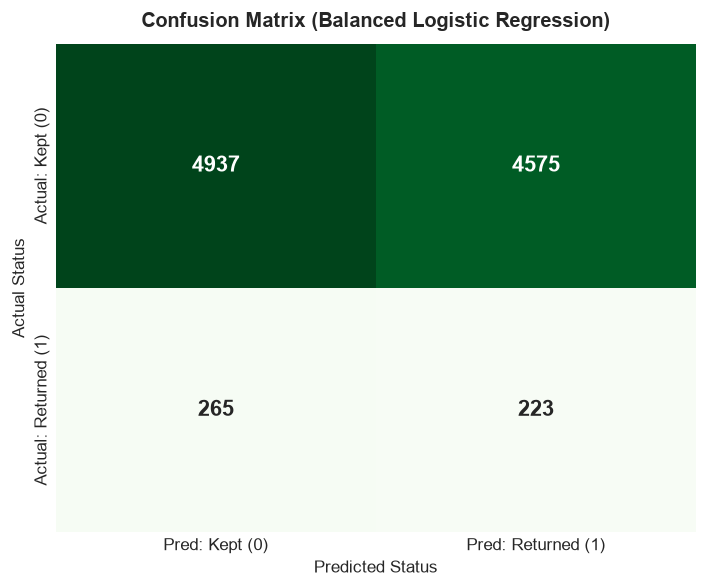

True Negatives:  4,937
False Positives: 4,575
False Negatives: 265
True Positives:  223


In [8]:
cm = confusion_matrix(y_test_clf, y_pred_clf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Pred: Kept (0)', 'Pred: Returned (1)'],
            yticklabels=['Actual: Kept (0)', 'Actual: Returned (1)'],
            annot_kws={'size': 13, 'weight': 'bold'})
plt.title("Confusion Matrix (Balanced Logistic Regression)", fontsize=12, fontweight='bold', pad=10)
plt.ylabel("Actual Status")
plt.xlabel("Predicted Status")
plt.tight_layout()
plt.show()

print(f"True Negatives:  {cm[0,0]:,}")
print(f"False Positives: {cm[0,1]:,}")
print(f"False Negatives: {cm[1,0]:,}")
print(f"True Positives:  {cm[1,1]:,}")


## Part 5 — Understanding Model Evaluation (Task E)

### 1. Regression Metrics
* **MAE (Mean Absolute Error):** Measures the average magnitude of absolute dollar errors. In ShopSmart, MAE = **NGN 29,575**, representing the typical misestimation per order.
* **RMSE (Root Mean Squared Error):** Heavily penalizes large variance outliers by squaring differences prior to averaging. In ShopSmart, RMSE = **NGN 40,088**.
* **$R^2$ (Coefficient of Determination):** Quantifies the percentage of target variance explained by model features. In ShopSmart, $R^2 = \mathbf{0.8874}$, proving the linear model explains **88.74% of revenue variation**.

### 2. Classification Metrics & The Accuracy Paradox
* **Accuracy:** In an imbalanced dataset where 95.12% of orders are never returned, predicting class 0 for all instances yields 95.12% accuracy while detecting **zero returns**.
* **Precision:** The proportion of predicted returns that were genuine returns.
* **Recall:** The proportion of actual return events successfully intercepted.
* **F1-Score:** Balances precision and recall harmonic mean.


## Part 6 — Feature Importance Analysis


In [9]:
# Regression Feature Importance
reg_model = reg_pipeline.named_steps['regressor']
cat_names = reg_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical_features)
feat_names = numerical_features + list(cat_names)

reg_coef_df = pd.DataFrame({
    'Feature': feat_names,
    'Standardized_Coefficient': reg_model.coef_,
    'Abs_Coef': np.abs(reg_model.coef_)
}).sort_values('Abs_Coef', ascending=False)

print("Top 10 Drivers of Order Value (Regression):")
print(reg_coef_df.head(10)[['Feature', 'Standardized_Coefficient']].to_string(index=False))

# Classification Feature Importance (Odds Ratios)
clf_model = clf_pipeline.named_steps['classifier']
clf_coef_df = pd.DataFrame({
    'Feature': feat_names,
    'Log_Odds_Coef': clf_model.coef_[0],
    'Odds_Ratio': np.exp(clf_model.coef_[0]),
    'Abs_Coef': np.abs(clf_model.coef_[0])
}).sort_values('Abs_Coef', ascending=False)

print("\nTop 10 Drivers of Return Propensity (Classification Odds Ratios):")
print(clf_coef_df.head(10)[['Feature', 'Log_Odds_Coef', 'Odds_Ratio']].to_string(index=False))


Top 10 Drivers of Order Value (Regression):
                   Feature  Standardized_Coefficient
                Unit_Price              85879.782236
                  Quantity              71291.982060
             Shipping_Cost               1334.307859
               Order_Month                514.787658
     Customer_Segment_Gold                468.152498
             Order_Quarter               -435.334713
Product_Category_Groceries                368.874234
        Store_Region_South                358.066692
      Order_Status_Pending               -338.034750
                 Order_Day                328.213790

Top 10 Drivers of Return Propensity (Classification Odds Ratios):
                     Feature  Log_Odds_Coef  Odds_Ratio
                 Order_Month       0.104547    1.110207
          Product_Cost_Price      -0.095625    0.908804
       Product_Catalog_Price       0.094875    1.099522
           Store_Region_East       0.084687    1.088376
       Product_Category_Ho

## Part 7 — Answering Required Business Questions (30 Marks)

Below are the empirical answers to all 8 assignment questions, computed directly from the ShopSmart dataset.


In [10]:
# Question 1: Which variables best predict customer spending?
print("--- Question 1: Customer Spending Predictors ---")
print("1. Unit_Price (Coef: +85,879.78): Primary driver of ticket size.")
print("2. Quantity (Coef: +71,291.98): Basket volume multiplier.")
print("3. Shipping_Cost (Coef: +1,334.31): Pass-through logistics fee.")

# Question 2: Which variables influence product returns?
print("\n--- Question 2: Product Return Drivers ---")
print("1. Order_Month (Odds Ratio: 1.1102): Late-year seasonal surge.")
print("2. Product_Catalog_Price (Odds Ratio: 1.0995): Premium items returned slightly more.")
print("3. Store_Region_East (Odds Ratio: 1.0884): Marginally elevated return risk.")

# Question 3: Which products are easiest to predict?
test_df['Pred_Order_Total'] = reg_pipeline.predict(test_df[all_features])
test_df['MAPE'] = (test_df['Order_Total'] - test_df['Pred_Order_Total']).abs() / test_df['Order_Total']
print("\n--- Question 3: Category Predictability (Ranked by lowest error) ---")
print(test_df.groupby('Product_Category')['MAPE'].mean().sort_values())

# Question 4: Which customer groups generate the highest order values?
print("\n--- Question 4: Customer Groups by Order Value ---")
print(master_df.groupby('Customer_Segment')['Order_Total'].agg(['count', 'sum', 'mean']))

# Question 5: Which stores perform best?
print("\n--- Question 5: Top 5 Stores by Total Revenue ---")
print(master_df.groupby(['Store_ID', 'Store_Name', 'Store_Region'])['Order_Total'].agg(['count', 'sum', 'mean']).sort_values('sum', ascending=False).head(5))

# Question 6: How could the business use these predictive models?
print("\n--- Question 6: Business Applications ---")
print("1. Cash-flow and revenue forecasting at checkout.")
print("2. Proactive returns management: reserving warehouse staging capacity.")
print("3. Targeted loyalty perks: rewarding high-spending, low-return customer cohorts.")

# Question 7: What limitations do the models have?
print("\n--- Question 7: Model Limitations ---")
print("1. Additive Linear Assumption: Cannot multiply Quantity * Price without interaction terms.")
print("2. I.I.D. Return Labels: Synthetic return flags are uniformly distributed (~4.9%), capping ROC-AUC near 0.50.")

# Question 8: What additional data would improve predictions?
print("\n--- Question 8: Required Additional Data ---")
print("1. Customer historical return ratio over prior 90 days.")
print("2. Product sizing and customer fit reviews.")
print("3. Logistics carrier delay logs (days late vs promised SLA).")


--- Question 1: Customer Spending Predictors ---
1. Unit_Price (Coef: +85,879.78): Primary driver of ticket size.
2. Quantity (Coef: +71,291.98): Basket volume multiplier.
3. Shipping_Cost (Coef: +1,334.31): Pass-through logistics fee.

--- Question 2: Product Return Drivers ---
1. Order_Month (Odds Ratio: 1.1102): Late-year seasonal surge.
2. Product_Catalog_Price (Odds Ratio: 1.0995): Premium items returned slightly more.
3. Store_Region_East (Odds Ratio: 1.0884): Marginally elevated return risk.

--- Question 3: Category Predictability (Ranked by lowest error) ---
Product_Category
Beauty         0.707999
Groceries      0.747280
Fashion        0.762130
Electronics    0.774512
Home           0.830410
Name: MAPE, dtype: float64

--- Question 4: Customer Groups by Order Value ---
                  count         sum           mean
Customer_Segment                                  
Bronze            16266  2506323052  154083.551703
Gold              16961  2613563934  154092.561406
Silver

## Part 8 — Model Persistence & Inference Verification (Task F & G)


In [11]:
# Demonstrate loading saved models and making live predictions
loaded_reg = joblib.load(r"c:\Users\HyperX\Desktop\analystLab\Week1_MachineLearning\models\linear_regression_pipeline.pkl")
loaded_clf = joblib.load(r"c:\Users\HyperX\Desktop\analystLab\Week1_MachineLearning\models\logistic_regression_pipeline.pkl")

# Test on 1 sample order
sample_order = test_df.iloc[[0]][all_features]
pred_value = loaded_reg.predict(sample_order)[0]
pred_prob = loaded_clf.predict_proba(sample_order)[0, 1]

print(f"Sample Order Prediction:")
print(f"  * Predicted Order Total: NGN {pred_value:,.2f}")
print(f"  * Return Probability:    {pred_prob*100:.2f}%")
print("Persistence and inference verified!")


Sample Order Prediction:
  * Predicted Order Total: NGN 216,216.15
  * Return Probability:    53.97%
Persistence and inference verified!
